# 3-laboratoriya ishi: tavsiflovchi statistika, GroupBy, korrelyatsiya va ANOVA

**Maʼlumotlar:** `input/cars.csv` — 398 ta avtomobil (Auto MPG toʻplami, 1970–1982-yillar).

**Amaliy topshiriq:** avtomobillar toʻplami uchun **muhim uzluksiz** va **muhim kategorik** oʻzgaruvchilarni topish.

**Maqsad oʻzgaruvchi — `mpg`** (*miles per gallon*): mashina 1 gallon (≈ 3.8 litr) yoqilgʻida necha mil (1 mil ≈ 1.6 km) yuradi. `mpg` qancha katta boʻlsa, mashina shuncha tejamkor. Maʼruzada maqsad oʻzgaruvchi `price` (narx) edi, bizning toʻplamda narx yoʻq. Shuning uchun savol shunday: **`mpg` ga qaysi oʻzgaruvchilar eng koʻp taʼsir qiladi?**

| № | Boʻlim | Nima qilinadi |
|---|---|---|
| 1 | Maʼlumotlarni yuklash | `input/` papkadan oʻqish, ustun turlari, NaN |
| 2 | Formulalarni qoʻlda hisoblash | 10 ta son bilan: min, max, oʻrtacha, median, kvartillar, IQR, outlier, std |
| 3 | Tavsiflovchi statistika | `describe()`, `value_counts()`, outlierlar, box plot |
| 4 | GroupBy | `groupby()`, agregat funksiyalar, pivot jadval, heatmap (`pcolor`, qizil–koʻk) |
| 5 | Korrelyatsiya | Pearson (qoʻlda va `scipy` bilan), p-qiymat, regressiya chizigʻi, korrelyatsion heatmap |
| 6 | ANOVA | F-test va p-qiymat (formula bilan va `scipy` bilan) |
| 7 | Xulosa | muhim uzluksiz va kategorik oʻzgaruvchilar |

In [1]:
# Kerakli kutubxonalar
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

%matplotlib inline

# seaborn 0.12 va pandas 2.x birga ishlaganda chiqadigan texnik ogohlantirishlarni yashiramiz
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 3)

# Grafiklar uchun yagona sokin uslub: ingichka oʻqlar, yengil toʻr chiziqlar
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})

ASOSIY_RANG = "#2a78d6"   # koʻk — asosiy maʼlumotlar
URGU_RANG = "#eb6834"     # toʻq sariq — urgʻu (outlier, regressiya chizigʻi)
ORIGIN_TARTIB = ["usa", "europe", "japan"]

# Box plot uslubi: och koʻk quti, qora median, toʻq sariq outlier nuqtalar
BOX_USLUB = {
    "boxprops": {"facecolor": "#cde2fb", "edgecolor": ASOSIY_RANG, "linewidth": 1.5},
    "whiskerprops": {"color": ASOSIY_RANG, "linewidth": 1.5},
    "capprops": {"color": ASOSIY_RANG, "linewidth": 1.5},
    "medianprops": {"color": "#0b0b0b", "linewidth": 2},
    "flierprops": {"marker": "o", "markersize": 7, "markerfacecolor": URGU_RANG,
                   "markeredgecolor": "#fcfcfb", "markeredgewidth": 1},
}

## 1. Maʼlumotlarni yuklash

In [2]:
# Maʼlumotlar shu notebook yonidagi input/ papkasida
df = pd.read_csv("input/cars.csv")

print("Qatorlar soni:", df.shape[0], "| ustunlar soni:", df.shape[1])
df.head()

Qatorlar soni: 398 | ustunlar soni: 9


,name,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
0,chevrolet chevelle malibu,18.0,8,307.0,130.0,3504,12.0,70,usa
1,buick skylark 320,15.0,8,350.0,165.0,3693,11.5,70,usa
2,plymouth satellite,18.0,8,318.0,150.0,3436,11.0,70,usa
3,amc rebel sst,16.0,8,304.0,150.0,3433,12.0,70,usa
4,ford torino,17.0,8,302.0,140.0,3449,10.5,70,usa


In [3]:
# Har bir ustunning turi, boʻsh (NaN) qiymatlar soni va nechta xil qiymat borligi
pd.DataFrame({
    "turi": df.dtypes,
    "NaN soni": df.isna().sum(),
    "xil qiymatlar soni": df.nunique(),
})

,turi,NaN soni,xil qiymatlar soni
name,str,0,305
mpg,float64,0,129
cylinders,int64,0,5
displacement,float64,0,82
horsepower,float64,6,93
weight,int64,0,351
acceleration,float64,0,95
model_year,int64,0,13
origin,str,0,3


**Natija:** faqat `horsepower` ustunida 6 ta boʻsh qiymat (NaN) bor. `describe()`, `mean()`, `groupby()` kabi funksiyalar NaN ni **avtomatik tashlab ketadi**. `stats.pearsonr()` esa NaN ni qabul qilmaydi, shuning uchun korrelyatsiyada bu 6 ta qatorni olib tashlaymiz.

### Oʻzgaruvchilar turlari

| Ustun | Maʼnosi | Turi |
|---|---|---|
| `mpg` | yoqilgʻi tejamkorligi (mil/gallon) | uzluksiz — **maqsad** |
| `displacement` | dvigatel hajmi (kub dyuym) | uzluksiz |
| `horsepower` | dvigatel quvvati (ot kuchi) | uzluksiz |
| `weight` | mashina ogʻirligi (funt) | uzluksiz |
| `acceleration` | 0 dan 60 mil/soat tezlikka chiqish vaqti (soniya); **katta qiymat — sekin mashina** | uzluksiz |
| `model_year` | ishlab chiqarilgan yil (70 = 1970) | diskret, tartibli — son sifatida koʻramiz |
| `cylinders` | silindrlar soni | **kategorik** — atigi 5 xil qiymat (3, 4, 5, 6, 8) |
| `origin` | ishlab chiqarilgan joy | **kategorik** — usa, europe, japan |
| `name` | mashina nomi | identifikator — 305 xil nom, tahlilda ishlatilmaydi |

- **Uzluksiz oʻzgaruvchi** — istalgan sonni olishi mumkin (masalan, 2130.5 funt).
- **Kategorik oʻzgaruvchi** — bir nechta guruhdan birini oladi (masalan, usa / europe / japan).

## 2. Formulalarni qoʻlda hisoblash (10 ta son)

Formulani qogʻozda oʻzingiz hisoblasangiz, u esda yaxshiroq qoladi. Toʻplamdan tasodifiy **10 ta mashina** olamiz va ularning `horsepower` (ot kuchi) qiymatlari bilan ishlaymiz. **Avval qogʻozda hisoblang, keyin kod bilan tekshiring.**

In [4]:
# random_state=4 — har safar aynan shu 10 ta mashina chiqishi uchun
namuna = df.sample(10, random_state=4)[["name", "horsepower", "mpg", "origin"]]
namuna

,name,horsepower,mpg,origin
303,datsun 210,65.0,31.8,japan
6,chevrolet impala,220.0,14.0,usa
61,ford pinto runabout,86.0,21.0,usa
310,toyota corolla tercel,60.0,38.1,japan
100,ford maverick,88.0,18.0,usa
272,oldsmobile starfire sx,85.0,23.8,usa
329,honda civic 1500 gl,67.0,44.6,japan
380,nissan stanza xe,88.0,36.0,japan
226,buick skylark,105.0,20.5,usa
328,mercedes-benz 240d,67.0,30.0,europe


### Qoʻlda hisoblash

**1-qadam. Tartiblash** (kichikdan kattaga), $n = 10$:

$$60,\ 65,\ 67,\ 67,\ 85,\ 86,\ 88,\ 88,\ 105,\ 220$$

**2-qadam. Min, max va oraliq (range)**

$$\min = 60, \qquad \max = 220, \qquad \text{range} = \max - \min = 220 - 60 = 160$$

**3-qadam. Oʻrtacha qiymat (mean)**

$$\bar{x} = \frac{\sum x_i}{n} = \frac{60+65+67+67+85+86+88+88+105+220}{10} = \frac{931}{10} = 93.1$$

**4-qadam. Median** — tartiblangan qatorning oʻrtasidagi qiymat. $n$ juft boʻlgani uchun oʻrtadagi ikki sonning (5- va 6-sonlar) oʻrtachasini olamiz. ($n$ toq boʻlsa, toʻppa-toʻgʻri oʻrtadagi son olinadi.)

$$Me = \frac{x_5 + x_6}{2} = \frac{85 + 86}{2} = 85.5$$

**5-qadam. Kvartillar.** Q1 — qiymatlarning 25 % i undan kichik, Q3 — 75 % i undan kichik. Pandas usuli: $p$-kvantilning oʻrni $= (n-1)\cdot p + 1$.

- Q1: oʻrin $= 9 \cdot 0.25 + 1 = 3.25$ → $Q_1 = x_3 + 0.25\cdot(x_4 - x_3) = 67 + 0.25\cdot(67 - 67) = 67$
- Q3: oʻrin $= 9 \cdot 0.75 + 1 = 7.75$ → $Q_3 = x_7 + 0.75\cdot(x_8 - x_7) = 88 + 0.75\cdot(88 - 88) = 88$

> Darsliklardagi boshqa usul: Q1 — pastki yarim (60, 65, 67, 67, 85) medianasi = 67, Q3 — yuqori yarim (86, 88, 88, 105, 220) medianasi = 88. Bu misolda ikkala usul bir xil natija beradi.

**6-qadam. IQR va outlier chegaralari**

$$IQR = Q_3 - Q_1 = 88 - 67 = 21$$

$$\text{pastki chegara} = Q_1 - 1.5\cdot IQR = 67 - 31.5 = 35.5$$

$$\text{yuqori chegara} = Q_3 + 1.5\cdot IQR = 88 + 31.5 = 119.5$$

35.5 dan kichik yoki 119.5 dan katta qiymat — **outlier** (chetga chiqqan qiymat). Bizda bitta outlier bor: **220** (*chevrolet impala* — katta 8 silindrli mashina).

**7-qadam. Dispersiya va standart ogʻish (std)** — qiymatlar oʻrtachadan qanchalik uzoqlashganini koʻrsatadi:

$$s^2 = \frac{\sum (x_i - \bar{x})^2}{n - 1}, \qquad s = \sqrt{s^2}$$

| $x_i$ | $x_i - \bar{x}$ | $(x_i - \bar{x})^2$ |
|---:|---:|---:|
| 60 | −33.1 | 1095.61 |
| 65 | −28.1 | 789.61 |
| 67 | −26.1 | 681.21 |
| 67 | −26.1 | 681.21 |
| 85 | −8.1 | 65.61 |
| 86 | −7.1 | 50.41 |
| 88 | −5.1 | 26.01 |
| 88 | −5.1 | 26.01 |
| 105 | 11.9 | 141.61 |
| 220 | 126.9 | 16103.61 |
| **Σ = 931** | **0** | **19660.90** |

$$s^2 = \frac{19660.9}{9} = 2184.54, \qquad s = \sqrt{2184.54} \approx 46.74$$

### Nimani koʻrdik?
- Oʻrtacha (93.1) mediandan (85.5) katta: bitta katta son (220) oʻrtachani yuqoriga tortib ketdi.
- 220 ni olib tashlasak, oʻrtacha $711 / 9 = 79.0$ ga tushadi (14 birlikka!), median esa $85$ boʻladi (deyarli oʻzgarmaydi).
- Yigʻindi 19660.9 ning 16103.61 qismi (82 %) birgina 220 dan keladi — std ham outlierga juda sezgir.
- **Xulosa: median outlierlarga chidamli, oʻrtacha va std esa sezgir.** Maʼlumotda outlier boʻlsa, medianga ham albatta qarang.

In [5]:
# Xuddi shu hisob — formulalar orqali, pandas'ning tayyor statistik funksiyalarisiz
x = sorted(namuna["horsepower"].astype(int).tolist())
n = len(x)


def kvantil(tartiblangan, p):
    """Pandas usuli: (n-1)*p oʻrindagi qiymat; oʻrin kasr boʻlsa — chiziqli interpolyatsiya."""
    orin = (len(tartiblangan) - 1) * p     # 0 dan boshlab sanalgan oʻrin
    i = int(orin)                           # butun qismi
    kasr = orin - i                         # kasr qismi
    if i + 1 == len(tartiblangan):
        return tartiblangan[i]
    return tartiblangan[i] + kasr * (tartiblangan[i + 1] - tartiblangan[i])


ortacha = sum(x) / n
mediana = (x[n // 2 - 1] + x[n // 2]) / 2 if n % 2 == 0 else x[n // 2]
q1, q3 = kvantil(x, 0.25), kvantil(x, 0.75)
iqr_qiymat = q3 - q1
past_chegara = q1 - 1.5 * iqr_qiymat
yuqori_chegara = q3 + 1.5 * iqr_qiymat
outlierlar = [xi for xi in x if xi < past_chegara or xi > yuqori_chegara]
dispersiya = sum((xi - ortacha) ** 2 for xi in x) / (n - 1)
std = dispersiya ** 0.5

print("Tartiblangan qiymatlar:", x)
print(f"min = {x[0]}, max = {x[-1]}, range = {x[-1] - x[0]}")
print(f"oʻrtacha = {ortacha:.1f}, median = {mediana}")
print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr_qiymat}")
print(f"chegaralar: [{past_chegara}, {yuqori_chegara}]  ->  outlierlar: {outlierlar}")
print(f"dispersiya = {dispersiya:.2f}, std = {std:.2f}")

Tartiblangan qiymatlar: [60, 65, 67, 67, 85, 86, 88, 88, 105, 220]
min = 60, max = 220, range = 160
oʻrtacha = 93.1, median = 85.5
Q1 = 67.0, Q3 = 88.0, IQR = 21.0
chegaralar: [35.5, 119.5]  ->  outlierlar: [220]
dispersiya = 2184.54, std = 46.74


In [6]:
# Tekshirish: pandas'ning tayyor funksiyasi xuddi shu natijalarni beradi
namuna["horsepower"].describe()

count     10.000
mean      93.100
std       46.739
min       60.000
25%       67.000
50%       85.500
75%       88.000
max      220.000
Name: horsepower, dtype: float64

### Shu 10 ta son box plot'da

Box plot yuqoridagi hisoblarni bitta rasmda koʻrsatadi:
- **quti** — Q1 dan Q3 gacha (IQR), ichidagi qora chiziq — **median**;
- **moʻylovlar** (whiskers) — chegaralar ichidagi eng kichik va eng katta qiymatgacha (60 va 105);
- chegaradan tashqaridagi qiymat — **alohida nuqta (outlier)**.

/var/folders/r4/847h6_9s0vj93ym2b365tvdm0000gn/T/ipykernel_57893/1036972892.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(x, vert=False, widths=0.4, patch_artist=True, **BOX_USLUB)


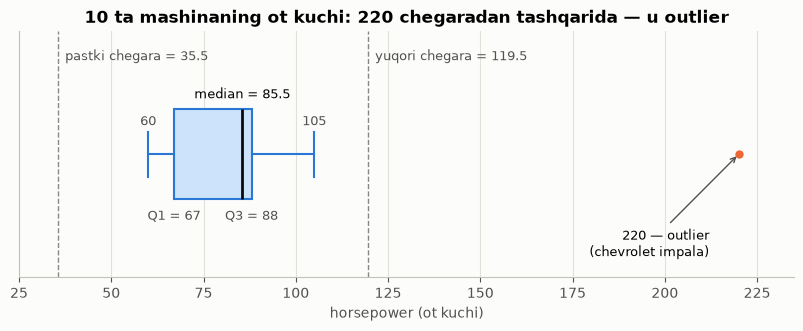

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.boxplot(x, vert=False, widths=0.4, patch_artist=True, **BOX_USLUB)

# Outlier chegaralari (shtrix chiziqlar)
for chegara, nom in [(past_chegara, "pastki chegara"), (yuqori_chegara, "yuqori chegara")]:
    ax.axvline(chegara, color="#898781", linestyle="--", linewidth=1)
    ax.text(chegara + 2, 1.42, f"{nom} = {chegara}", color="#52514e", fontsize=9)

# Asosiy qiymatlarni yozib qoʻyamiz
ax.text(mediana, 1.25, f"median = {mediana}", ha="center", fontsize=9)
ax.text(q1, 0.75, f"Q1 = {q1:g}", ha="center", va="top", color="#52514e", fontsize=9)
ax.text(q3, 0.75, f"Q3 = {q3:g}", ha="center", va="top", color="#52514e", fontsize=9)
for moylov in (min(x), 105):
    ax.text(moylov, 1.13, f"{moylov}", ha="center", color="#52514e", fontsize=9)
ax.annotate("220 — outlier\n(chevrolet impala)", xy=(220, 1), xytext=(212, 0.6),
            ha="right", va="center", fontsize=9,
            arrowprops={"arrowstyle": "->", "color": "#52514e"})

ax.set_xlim(25, 235)
ax.set_ylim(0.45, 1.55)
ax.set_yticks([])
ax.grid(axis="x")
ax.set_xlabel("horsepower (ot kuchi)")
ax.set_title("10 ta mashinaning ot kuchi: 220 chegaradan tashqarida — u outlier")
plt.show()

## 3. Tavsiflovchi statistika

Murakkab model qurishdan oldin maʼlumot bilan yaqindan tanishish kerak. **Tavsiflovchi statistika** — maʼlumotning qisqa "pasporti": nechta qiymat bor, oʻrtachasi qancha, qanchalik tarqoq, eng kichik va eng katta qiymatlari qanday.

### 3.1. Uzluksiz oʻzgaruvchilar — `describe()`
`describe()` barcha son ustunlar uchun asosiy statistikani bir yoʻla hisoblaydi (NaN qiymatlar avtomatik tashlab ketiladi).

In [8]:
df.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000,398.000,398.000,392.000,398.000,398.000,398.000
mean,23.515,5.455,193.426,104.469,2970.425,15.568,76.010
std,7.816,1.701,104.270,38.491,846.842,2.758,3.698
min,9.000,3.000,68.000,46.000,1613.000,8.000,70.000
25%,17.500,4.000,104.250,75.000,2223.750,13.825,73.000
50%,23.000,4.000,148.500,93.500,2803.500,15.500,76.000
75%,29.000,8.000,262.000,126.000,3608.000,17.175,79.000
max,46.600,8.000,455.000,230.000,5140.000,24.800,82.000


| Qator | Maʼnosi |
|---|---|
| `count` | NaN boʻlmagan qiymatlar soni (`horsepower` da 392 — 6 ta NaN tashlab ketilgan) |
| `mean` | oʻrtacha qiymat |
| `std` | standart ogʻish — qiymatlar oʻrtachadan qanchalik tarqoq |
| `min` / `max` | eng kichik / eng katta qiymat |
| `25%` / `50%` / `75%` | Q1 / **median** / Q3 |

**Kuzatish:** `mpg` 9 dan 46.6 gacha, oʻrtachasi 23.5, medianasi 23.0 — oʻrtacha va median yaqin, demak `mpg` da kuchli outlierlar kam. `weight` 1613 dan 5140 funtgacha — eng ogʻir mashina eng yengilidan 3 baravardan ham ogʻirroq.

### 3.2. Kategorik oʻzgaruvchilar — `value_counts()`
Kategorik oʻzgaruvchida oʻrtacha emas, **har bir guruhda nechta qiymat borligi** muhim. Buni `value_counts()` hisoblaydi.

In [9]:
# Har bir guruhda nechta mashina bor va bu umumiy sonning necha foizi
for ustun in ["origin", "cylinders"]:
    jadval = pd.DataFrame({
        "soni": df[ustun].value_counts(),
        "ulushi (%)": (df[ustun].value_counts(normalize=True) * 100).round(1),
    })
    display(jadval)

,soni,ulushi (%)
origin,,
usa,249,62.6
japan,79,19.8
europe,70,17.6


,soni,ulushi (%)
cylinders,,
4,204,51.3
8,103,25.9
6,84,21.1
3,4,1.0
5,3,0.8


**Kuzatish:** mashinalarning 62.6 % i AQSHda ishlab chiqarilgan. 3 silindrli (4 ta — hammasi rotorli dvigatelli Mazda RX) va 5 silindrli (3 ta — Audi va Mercedes) mashinalar juda kam, shuning uchun bu guruhlar boʻyicha xulosa chiqarishda ehtiyot boʻlish kerak.

### 3.3. Butun toʻplamda outlierlarni topish (oʻz funksiyamiz bilan)
2-boʻlimdagi IQR qoidasini funksiya qilib yozamiz va `apply()` yordamida har bir uzluksiz ustunga qoʻllaymiz.

In [10]:
def outlier_hisobot(ustun):
    """IQR qoidasi: Q1 - 1.5*IQR dan kichik yoki Q3 + 1.5*IQR dan katta qiymat — outlier."""
    q1, q3 = ustun.quantile(0.25), ustun.quantile(0.75)
    iqr = q3 - q1
    past, yuqori = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "pastki chegara": past,
        "yuqori chegara": yuqori,
        "outlierlar soni": ((ustun < past) | (ustun > yuqori)).sum(),
    })


uzluksiz = ["mpg", "displacement", "horsepower", "weight", "acceleration"]
df[uzluksiz].apply(outlier_hisobot).T.astype({"outlierlar soni": int})

,Q1,Q3,IQR,pastki chegara,yuqori chegara,outlierlar soni
mpg,17.500,29.000,11.50,0.250,46.250,1
displacement,104.250,262.000,157.75,-132.375,498.625,0
horsepower,75.000,126.000,51.00,-1.500,202.500,10
weight,2223.750,3608.000,1384.25,147.375,5684.375,0
acceleration,13.825,17.175,3.35,8.800,22.200,7


In [ ]:
# Ot kuchi boʻyicha outlierlar — bular qanday mashinalar?
hp_chegara = outlier_hisobot(df["horsepower"])["yuqori chegara"]
df[df["horsepower"] > hp_chegara][["name", "horsepower", "cylinders", "weight", "mpg", "model_year"]].sort_values("horsepower")

**Kuzatish:** `horsepower` da 10 ta, `acceleration` da 7 ta, `mpg` da 1 ta outlier bor. Ular **xato emas**: masalan, ot kuchi outlierlari — 1970–1973-yillardagi haqiqiy kuchli 8 silindrli Amerika mashinalari (208–230 ot kuchi, 10–16 mpg). Shuning uchun ularni oʻchirmaymiz — outlier har doim ham "yomon" maʼlumot emas.

### 3.4. Tavsiflovchi statistikani vizualizatsiya qilish — box plot
Box plot guruhlar boʻyicha taqsimotni solishtirish uchun qulay:
- quti — Q1 dan Q3 gacha, ichidagi chiziq — median;
- moʻylovlar — $Q_1 - 1.5\cdot IQR$ va $Q_3 + 1.5\cdot IQR$ chegaralari ichidagi eng chetki qiymatlargacha;
- chegaradan tashqaridagi qiymatlar — alohida nuqtalar (outlierlar).

Guruhlarning qutilari bir-biridan qanchalik uzoq boʻlsa, bu kategorik oʻzgaruvchi `mpg` ga shunchalik kuchli taʼsir qiladi.

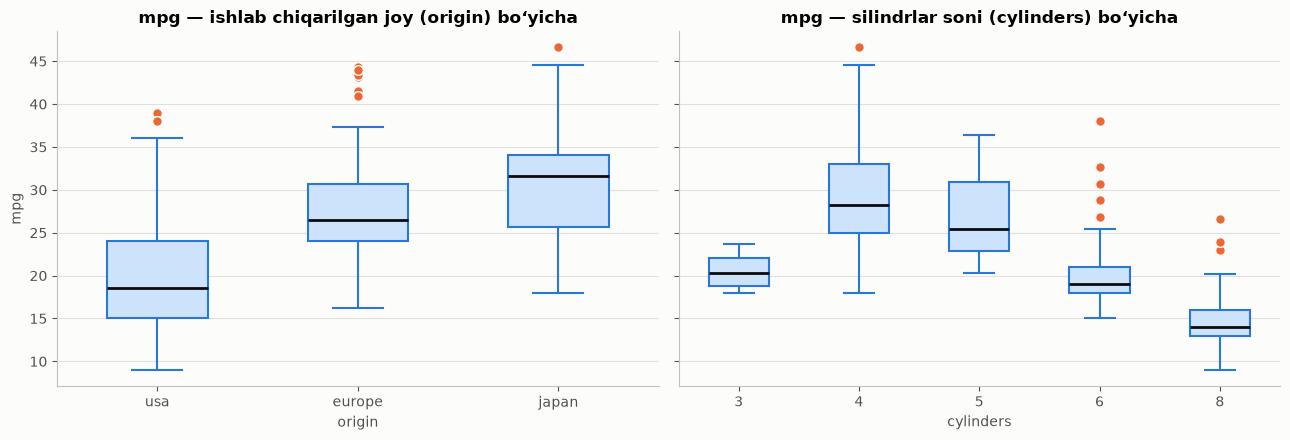

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

sns.boxplot(data=df, x="origin", y="mpg", order=ORIGIN_TARTIB, width=0.5, ax=axes[0], **BOX_USLUB)
axes[0].set_title("mpg — ishlab chiqarilgan joy (origin) boʻyicha")

sns.boxplot(data=df, x="cylinders", y="mpg", width=0.5, ax=axes[1], **BOX_USLUB)
axes[1].set_title("mpg — silindrlar soni (cylinders) boʻyicha")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Kuzatish:**
- AQSH mashinalarining `mpg` taqsimoti Yevropa va Yaponiya mashinalarinikidan ancha past. Yevropa va Yaponiya qutilari esa bir-birini koʻp qoplaydi — ular orasidagi farq kichikroq.
- Silindrlar koʻpaygani sari `mpg` keskin kamayadi: 4 silindrli mashinalar eng tejamkor, 8 silindrlilar eng koʻp yoqilgʻi sarflaydi.
- Ikkala oʻzgaruvchida ham guruhlar aniq farq qiladi → `origin` va `cylinders` **muhim kategorik oʻzgaruvchi boʻlishi mumkin**. Buni 6-boʻlimda ANOVA bilan tekshiramiz.

## 4. GroupBy — maʼlumotlarni guruhlash

`groupby()` maʼlumotni kategorik oʻzgaruvchining guruhlariga ajratadi va har bir guruh uchun alohida hisob qiladi. Uch qadam:
1. **ajratish (split)** — mashinalarni guruhlarga boʻlish (masalan, usa / europe / japan);
2. **hisoblash (apply)** — har bir guruhga funksiya qoʻllash (`mean`, `median`, `count`, ...);
3. **birlashtirish (combine)** — natijalarni bitta jadvalga yigʻish.

Bitta oʻzgaruvchi boʻyicha ham, bir nechta oʻzgaruvchi boʻyicha ham guruhlash mumkin.

### 4.1. Bitta oʻzgaruvchi boʻyicha guruhlash

In [12]:
# Har bir origin guruhidagi oʻrtacha mpg
df.groupby("origin")["mpg"].mean().sort_values(ascending=False)

origin
japan     30.451
europe    27.891
usa       20.084
Name: mpg, dtype: float64

Bir nechta funksiyani birdaniga qoʻllash uchun `agg()` ishlatiladi. Unga oʻzimiz yozgan funksiyani ham berish mumkin — masalan, IQR ni hisoblaydigan funksiyani:

In [13]:
def iqr(qiymatlar):
    """Kvartillararo oraliq: Q3 - Q1."""
    return qiymatlar.quantile(0.75) - qiymatlar.quantile(0.25)


for ustun in ["origin", "cylinders"]:
    display(df.groupby(ustun)["mpg"].agg(["count", "mean", "median", "min", "max", "std", iqr]))

,count,mean,median,min,max,std,iqr
origin,,,,,,,
europe,70,27.891,26.5,16.2,44.3,6.724,6.65
japan,79,30.451,31.6,18.0,46.6,6.090,8.35
usa,249,20.084,18.5,9.0,39.0,6.403,9.00


,count,mean,median,min,max,std,iqr
cylinders,,,,,,,
3,4,20.550,20.25,18.0,23.7,2.565,3.30
4,204,29.287,28.25,18.0,46.6,5.710,8.00
5,3,27.367,25.40,20.3,36.4,8.228,8.05
6,84,19.986,19.00,15.0,38.0,3.807,3.00
8,103,14.963,14.00,9.0,26.6,2.836,3.00


**Kuzatish:** Yaponiya mashinalari oʻrtacha 30.5 mpg, Yevropa — 27.9, AQSH — 20.1 mpg. Yaʼni Yaponiya mashinasi bir gallon yoqilgʻida AQSH mashinasiga qaraganda oʻrtacha ~10 mil koʻproq yuradi. 4 silindrli mashinalar oʻrtacha 29.3 mpg, 8 silindrlilar esa atigi 15.0 mpg.

### 4.2. Ikki oʻzgaruvchi boʻyicha guruhlash
Maʼruzadagi misolda qoʻzgʻatish tizimi va kuzov turi boʻyicha oʻrtacha narx topilgan edi. Bizda esa — **`origin` va `cylinders` boʻyicha oʻrtacha `mpg`**:
1. avval kerakli 3 ta ustunni tanlaymiz;
2. keyin ikki oʻzgaruvchi boʻyicha guruhlab, har bir kichik guruhning oʻrtacha `mpg` ini topamiz.

In [14]:
df_guruh = df[["origin", "cylinders", "mpg"]]
grouped = df_guruh.groupby(["origin", "cylinders"], as_index=False).mean()
grouped

,origin,cylinders,mpg
0,europe,4,28.411
1,europe,5,27.367
2,europe,6,20.100
3,japan,3,20.550
4,japan,4,31.596
5,japan,6,23.883
6,usa,4,27.840
7,usa,6,19.664
8,usa,8,14.963


### 4.3. Pivot jadval
Yuqoridagi "uzun" jadvalni oʻqish oson, lekin solishtirish qiyin. **Pivot** (Excel'dagi Pivot kabi) uni toʻrtburchak jadvalga aylantiradi: bitta oʻzgaruvchi qatorlarda (`origin`), ikkinchisi ustunlarda (`cylinders`).

In [15]:
grouped_pivot = grouped.pivot(index="origin", columns="cylinders", values="mpg")
grouped_pivot = grouped_pivot.reindex(ORIGIN_TARTIB)   # qatorlar tartibi: usa, europe, japan
grouped_pivot

cylinders,3,4,5,6,8
origin,,,,,
usa,NaN,27.840,NaN,19.664,14.963
europe,NaN,28.411,27.367,20.100,NaN
japan,20.55,31.596,NaN,23.883,NaN


`NaN` — bunday mashina yoʻq degani (masalan, Yevropa va Yaponiyada 8 silindrli mashina yoʻq). Har bir katakda nechta mashina borligini `pd.crosstab()` koʻrsatadi:

In [16]:
pd.crosstab(df["origin"], df["cylinders"]).reindex(ORIGIN_TARTIB)

cylinders,3,4,5,6,8
origin,,,,,
usa,0,72,0,74,103
europe,0,63,3,4,0
japan,4,69,0,6,0


### 4.4. Heatmap (issiqlik xaritasi)
Heatmap pivot jadvalni rangli toʻrga aylantiradi: har bir katak rangi oʻsha guruhning oʻrtacha `mpg` iga bogʻliq. Maʼruzadagidek `pyplot.pcolor()` va **qizil–koʻk (`RdBu`)** rang sxemasidan foydalanamiz: Y oʻqida — `origin`, X oʻqida — `cylinders`.

Rang shkalasining markazi — butun toʻplamning oʻrtacha `mpg` i (23.5): **qizil — oʻrtachadan kam tejamkor, koʻk — oʻrtachadan tejamkor**, oqqa yaqin — oʻrtachaga yaqin.

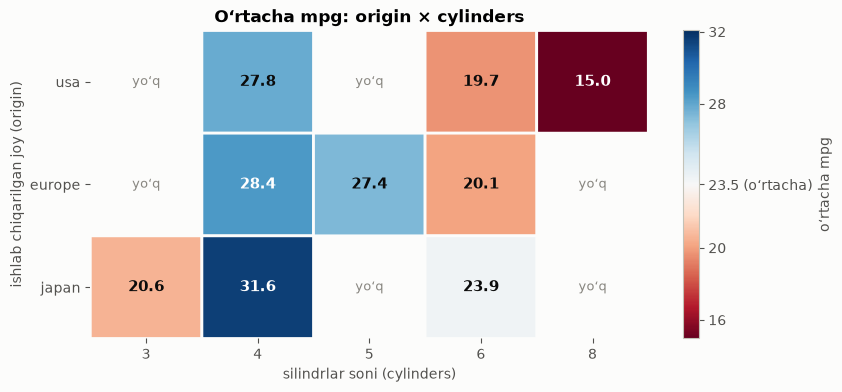

In [17]:
def qiymatlarni_yoz(ax, jadval, rangli, shablon="{:.1f}", bosh_matn=None):
    """Heatmap kataklariga qiymatlarni yozadi: toʻq katakda — oq, och katakda — qora harf."""
    for i in range(jadval.shape[0]):
        for j in range(jadval.shape[1]):
            qiymat = jadval.iloc[i, j]
            if pd.isna(qiymat):
                if bosh_matn:
                    ax.text(j + 0.5, i + 0.5, bosh_matn, ha="center", va="center", color="#898781", fontsize=9)
                continue
            r, g, b, _ = rangli.cmap(rangli.norm(qiymat))
            harf_rangi = "#0b0b0b" if 0.299 * r + 0.587 * g + 0.114 * b > 0.55 else "white"
            ax.text(j + 0.5, i + 0.5, shablon.format(qiymat), ha="center", va="center",
                    color=harf_rangi, fontsize=11, fontweight="bold")


ortacha_mpg = df["mpg"].mean()
chetlanish = (grouped_pivot - ortacha_mpg).abs().max().max()   # markazdan eng katta uzoqlik
qiymatlar = np.ma.masked_invalid(grouped_pivot.values)          # NaN kataklar boʻsh qoladi

fig, ax = plt.subplots(figsize=(9, 4))
im = ax.pcolor(qiymatlar, cmap="RdBu", vmin=ortacha_mpg - chetlanish, vmax=ortacha_mpg + chetlanish,
               edgecolors="#fcfcfb", linewidth=2)
im.set_array(qiymatlar)   # toʻliq 2D massiv (matplotlib 3.8 dagi ogohlantirish chiqmasligi uchun)

# Oʻq belgilari kataklarning oʻrtasida turadi
ax.set_xticks(np.arange(grouped_pivot.shape[1]) + 0.5, labels=grouped_pivot.columns)
ax.set_yticks(np.arange(grouped_pivot.shape[0]) + 0.5, labels=grouped_pivot.index)
ax.invert_yaxis()   # jadvaldagi kabi: usa — tepada
ax.grid(False)
ax.spines[:].set_visible(False)
ax.set_xlabel("silindrlar soni (cylinders)")
ax.set_ylabel("ishlab chiqarilgan joy (origin)")
ax.set_title("Oʻrtacha mpg: origin × cylinders")

qiymatlarni_yoz(ax, grouped_pivot, im, bosh_matn="yoʻq")

cbar = fig.colorbar(im, ax=ax)
cbar.set_ticks([16, 20, ortacha_mpg, 28, 32])
cbar.set_ticklabels(["16", "20", f"{ortacha_mpg:.1f} (oʻrtacha)", "28", "32"])
cbar.set_label("oʻrtacha mpg")
plt.show()

**Kuzatish:**
- Har bir silindr guruhi ichida **Yaponiya mashinalari eng tejamkor**: 4 silindrlilarda 31.6 mpg (Yevropa — 28.4, AQSH — 27.8), 6 silindrlilarda 23.9 mpg (Yevropa — 20.1, AQSH — 19.7).
- Silindrlar koʻpaygani sari rang qizilga oʻtadi: AQSHda 27.8 → 19.7 → 15.0 mpg.
- 8 silindrli mashinalar (103 ta) faqat AQSHda bor — AQSH oʻrtachasining pastligi qisman shundan. Lekin bir xil silindr sonida ham AQSH mashinalari kamroq tejamkor.
- Demak, `mpg` ga **ikkala kategorik oʻzgaruvchi ham taʼsir qiladi**.
- 3 silindrli Yaponiya mashinalari — 4 ta rotorli Mazda RX. Ular juda kam, shuning uchun bu katakka koʻp eʼtibor bermaymiz.

## 5. Korrelyatsiya

**Korrelyatsiya** — ikki oʻzgaruvchi birgalikda qanday oʻzgarishini oʻlchaydigan statistik koʻrsatkich: biri oshganda ikkinchisi ham oshadimi (musbat), kamayadimi (manfiy) yoki bogʻliqlik yoʻqmi.

**Korrelyatsiya ≠ sabab (causation):**
- *Yomgʻir va soyabon:* yomgʻir yoqqanda odamlar soyabon koʻtaradi — ular oʻzaro bogʻliq. Lekin soyabon yomgʻirga sabab emas.
- *Chekish va oʻpka saratoni:* bu yerda bogʻliqlik sabab-oqibat ekanini tibbiy tadqiqotlar isbotlagan.
- Korrelyatsiya faqat "birga oʻzgaradi" deydi, "biri ikkinchisini keltirib chiqaradi" demaydi.

### Pearson korrelyatsiyasi
Ikki uzluksiz oʻzgaruvchi $X$ va $Y$ orasidagi **chiziqli** bogʻliqlikni oʻlchaydi:

$$r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2 \cdot \sum (y_i - \bar{y})^2}}$$

| $r$ | Maʼnosi |
|---|---|
| $r = 1$ | toʻliq musbat chiziqli bogʻliqlik |
| $r = 0$ | chiziqli bogʻliqlik yoʻq |
| $r = -1$ | toʻliq manfiy chiziqli bogʻliqlik |

Taxminiy shkala: $|r| \ge 0.7$ — kuchli, $0.5$–$0.7$ — oʻrtacha, $0.3$–$0.5$ — kuchsiz, $< 0.3$ — juda kuchsiz.

### p-qiymat
p-qiymat — **"aslida bogʻliqlik yoʻq boʻlsa, bunday natija tasodifan chiqish ehtimoli"**. U qancha kichik boʻlsa, bogʻliqlik tasodif emasligiga shuncha koʻp ishonamiz. Odatda chegara 0.05 (95 % ishonch).

| p-qiymat | Xulosa |
|---|---|
| p < 0.001 | korrelyatsiya ahamiyatli ekaniga **kuchli** dalil |
| p < 0.05 | **oʻrtacha** dalil |
| p < 0.1 | **kuchsiz** dalil |
| p > 0.1 | dalil **yoʻq** |

In [18]:
# Korrelyatsiya hisoblari uchun horsepower boʻsh boʻlmagan mashinalar
df_toza = df.dropna(subset=["horsepower"])
print("Mashinalar soni:", len(df_toza))

Mashinalar soni: 392


### 5.1. Pearson koeffitsiyentini qoʻlda hisoblash (oʻsha 10 ta mashina)
$x$ — `horsepower`, $y$ — `mpg`. Jadvaldagi har bir ustunni qogʻozda hisoblab, oxirgi qatordagi yigʻindilar bilan solishtiring.

In [19]:
x = namuna["horsepower"]
y = namuna["mpg"]
dx = x - x.mean()   # x - x̄
dy = y - y.mean()   # y - ȳ

hisob = pd.DataFrame({
    "x (horsepower)": x,
    "y (mpg)": y,
    "x − x̄": dx,
    "y − ȳ": dy,
    "(x − x̄)(y − ȳ)": dx * dy,
    "(x − x̄)²": dx ** 2,
    "(y − ȳ)²": dy ** 2,
})
hisob.index = namuna["name"]                 # qatorlarni mashina nomi bilan belgilaymiz
hisob.loc["Σ (yigʻindi)"] = hisob.sum()
hisob.round(3) + 0.0                         # + 0.0: "-0.00" oʻrniga "0.00" koʻrinishi uchun

,x (horsepower),y (mpg),x − x̄,y − ȳ,(x − x̄)(y − ȳ),(x − x̄)²,(y − ȳ)²
name,,,,,,,
datsun 210,65.0,31.8,-28.1,4.02,-112.962,789.61,16.160
chevrolet impala,220.0,14.0,126.9,-13.78,-1748.682,16103.61,189.888
ford pinto runabout,86.0,21.0,-7.1,-6.78,48.138,50.41,45.968
toyota corolla tercel,60.0,38.1,-33.1,10.32,-341.592,1095.61,106.502
ford maverick,88.0,18.0,-5.1,-9.78,49.878,26.01,95.648
oldsmobile starfire sx,85.0,23.8,-8.1,-3.98,32.238,65.61,15.840
honda civic 1500 gl,67.0,44.6,-26.1,16.82,-439.002,681.21,282.912
nissan stanza xe,88.0,36.0,-5.1,8.22,-41.922,26.01,67.568
buick skylark,105.0,20.5,11.9,-7.28,-86.632,141.61,52.998


In [20]:
S = hisob.loc["Σ (yigʻindi)"]
r_qolda = S["(x − x̄)(y − ȳ)"] / np.sqrt(S["(x − x̄)²"] * S["(y − ȳ)²"])
r_scipy, p_scipy = stats.pearsonr(namuna["horsepower"], namuna["mpg"])

print(f"Qoʻlda (formula): r = {r_qolda:.4f}")
print(f"scipy.pearsonr:   r = {r_scipy:.4f},  p-qiymat = {p_scipy:.4f}")

Qoʻlda (formula): r = -0.6493
scipy.pearsonr:   r = -0.6493,  p-qiymat = 0.0422


$$\bar{x} = 93.1, \qquad \bar{y} = \frac{277.8}{10} = 27.78$$

$$r = \frac{-2698.48}{\sqrt{19660.9 \cdot 878.416}} = \frac{-2698.48}{4155.77} \approx -0.649$$

- $r \approx -0.65$ → **manfiy, oʻrtacha** bogʻliqlik: ot kuchi oshgani sari `mpg` kamayadi.
- $p \approx 0.042 < 0.05$ → **oʻrtacha dalil** (atigi 10 ta mashina boʻlgani uchun dalil unchalik kuchli emas).
- Quyida butun toʻplamda (392 ta mashina) xuddi shu juftlik uchun $r = -0.78$, $p \approx 7 \cdot 10^{-81}$ chiqadi — **maʼlumot qancha koʻp boʻlsa, xulosa shuncha ishonchli**.

### 5.2. Regressiya chizigʻi bilan scatter plot
Har bir nuqta — bitta mashina, chiziq — nuqtalarga eng yaxshi mos keladigan toʻgʻri chiziq (regressiya chizigʻi). Chiziq qanchalik qiya va nuqtalar unga qanchalik yaqin boʻlsa, bogʻliqlik shunchalik kuchli.

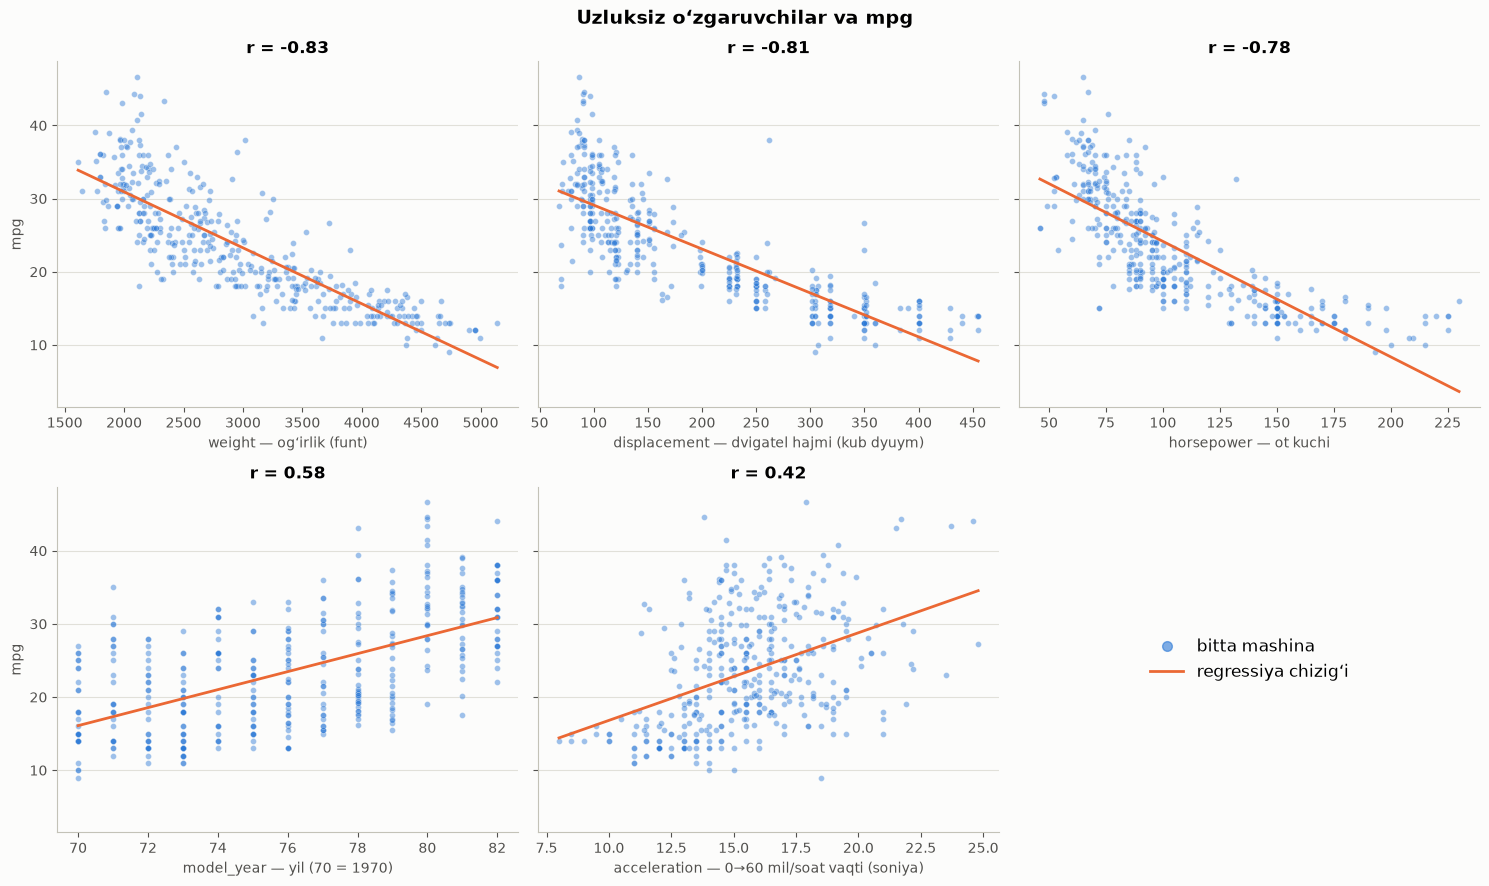

In [21]:
from matplotlib.lines import Line2D

belgilar = {
    "weight": "weight — ogʻirlik (funt)",
    "displacement": "displacement — dvigatel hajmi (kub dyuym)",
    "horsepower": "horsepower — ot kuchi",
    "model_year": "model_year — yil (70 = 1970)",
    "acceleration": "acceleration — 0→60 mil/soat vaqti (soniya)",
}

fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharey=True)
for i, (ustun, nom) in enumerate(belgilar.items()):
    ax = axes.flat[i]
    sns.regplot(data=df_toza, x=ustun, y="mpg", ci=None, ax=ax,
                scatter_kws={"s": 18, "alpha": 0.45, "color": ASOSIY_RANG,
                             "edgecolors": "#fcfcfb", "linewidths": 0.4},
                line_kws={"color": URGU_RANG, "linewidth": 2})
    r = df_toza[ustun].corr(df_toza["mpg"])
    ax.set_title(f"r = {r:.2f}")
    ax.set_xlabel(nom)
    if i % 3 != 0:
        ax.set_ylabel("")

# 6-katak boʻsh — u yerga belgilar izohini joylaymiz
izoh = axes.flat[5]
izoh.axis("off")
izoh.legend(handles=[
    Line2D([], [], marker="o", linestyle="", markersize=7, color=ASOSIY_RANG, alpha=0.6, label="bitta mashina"),
    Line2D([], [], color=URGU_RANG, linewidth=2, label="regressiya chizigʻi"),
], loc="center", frameon=False, fontsize=12)

fig.suptitle("Uzluksiz oʻzgaruvchilar va mpg", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Kuzatish:**
- `weight`, `displacement`, `horsepower`: chiziq keskin pastga tushadi, nuqtalar chiziq atrofida zich → **kuchli manfiy bogʻliqlik**: ogʻir, katta dvigatelli va kuchli mashinalar kam tejamkor.
- `model_year`: chiziq yuqoriga koʻtariladi → yangi mashinalar tejamkorroq (1970-yilda oʻrtacha 17.7 mpg, 1980-yilda 33.7 mpg; bu davrda 1973- va 1979-yillardagi neft inqirozlari tufayli tejamkor mashinalarga talab oshgan).
- `acceleration`: chiziq sal koʻtariladi, nuqtalar keng sochilgan → **kuchsiz musbat bogʻliqlik** (sekin tezlanadigan mashinalar biroz tejamkorroq).
- Eslatma: `weight` va `horsepower` bilan `mpg` orasidagi bogʻliqlik biroz egri chiziqqa oʻxshaydi. Pearson esa faqat **toʻgʻri chiziqli** bogʻliqlikni oʻlchaydi.

### 5.3. Pearson koeffitsiyenti va p-qiymat (butun toʻplam)
Maʼruzadagi kabi `stats.pearsonr()` ikkita qiymat qaytaradi: korrelyatsiya koeffitsiyenti va p-qiymat.

In [22]:
pearson_coef, p_value = stats.pearsonr(df_toza["weight"], df_toza["mpg"])
print("Pearson korrelyatsiya koeffitsiyenti:", pearson_coef, " P-qiymati: P =", p_value)

Pearson korrelyatsiya koeffitsiyenti: -0.832244214831575  P-qiymati: P = 6.015296051438847e-102


Endi barcha uzluksiz oʻzgaruvchilarni bitta jadvalda koʻramiz. Natijani soʻz bilan baholash uchun ikkita kichik funksiya yozamiz:

In [23]:
def bogliqlik_kuchi(r):
    """|r| boʻyicha taxminiy shkala."""
    r = abs(r)
    if r >= 0.7:
        return "kuchli"
    if r >= 0.5:
        return "oʻrtacha"
    if r >= 0.3:
        return "kuchsiz"
    return "juda kuchsiz"


def p_xulosa(p):
    """Maʼruzadagi p-qiymat jadvali."""
    if p < 0.001:
        return "kuchli dalil"
    if p < 0.05:
        return "oʻrtacha dalil"
    if p < 0.1:
        return "kuchsiz dalil"
    return "dalil yoʻq"


natijalar = []
for ustun in belgilar:
    r, p = stats.pearsonr(df_toza[ustun], df_toza["mpg"])
    natijalar.append({"oʻzgaruvchi": ustun, "r": r, "p-qiymat": p,
                      "bogʻliqlik kuchi": bogliqlik_kuchi(r), "p boʻyicha": p_xulosa(p)})

pearson_natija = pd.DataFrame(natijalar).set_index("oʻzgaruvchi")
pearson_natija

,r,p-qiymat,bogʻliqlik kuchi,p boʻyicha
oʻzgaruvchi,,,,
weight,-0.832,6.015e-102,kuchli,kuchli dalil
displacement,-0.805,1.661e-90,kuchli,kuchli dalil
horsepower,-0.778,7.032e-81,kuchli,kuchli dalil
model_year,0.581,1.076e-36,oʻrtacha,kuchli dalil
acceleration,0.423,1.779e-18,kuchsiz,kuchli dalil


**Kuzatish:**
- `weight` (r = −0.83), `displacement` (−0.81), `horsepower` (−0.78) — **kuchli manfiy** korrelyatsiya, p < 0.001.
- `model_year` (r = 0.58) — **oʻrtacha musbat**, p < 0.001.
- `acceleration` (r = 0.42) — **kuchsiz musbat**, p < 0.001: bogʻliqlik tasodifiy emas, lekin kuchsiz.
- Diqqat: p-qiymatning kichikligi bogʻliqlik **kuchli** degani emas — u faqat bogʻliqlik **tasodifiy emas** deydi. Kuchni $r$ koʻrsatadi.

### 5.4. Korrelyatsion heatmap
Barcha son ustunlar orasidagi korrelyatsiyani bitta rasmda koʻramiz. Rang: **koʻk — musbat, qizil — manfiy**, oqqa yaqin — bogʻliqlik yoʻq. Matritsa simmetrik boʻlgani uchun takrorlanuvchi yuqori qismini yashiramiz.

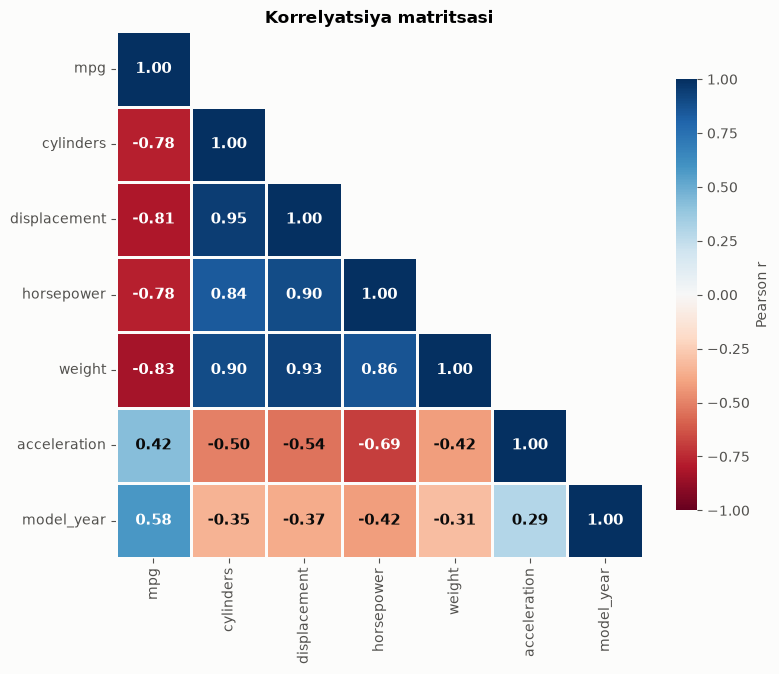

In [24]:
korr = df_toza.select_dtypes("number").corr()                 # Pearson korrelyatsiya matritsasi
yuqori_qism = np.triu(np.ones_like(korr, dtype=bool), k=1)    # diagonaldan yuqoridagi kataklar

fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(korr, mask=yuqori_qism, cmap="RdBu", vmin=-1, vmax=1, center=0,
            square=True, linewidths=2, linecolor="#fcfcfb",
            cbar_kws={"label": "Pearson r", "shrink": 0.8}, ax=ax)
# seaborn 0.12 + matplotlib 3.8 da annot=True faqat birinchi katakni yozadi,
# shuning uchun qiymatlarni 4.4-boʻlimdagi oʻz funksiyamiz bilan yozamiz
qiymatlarni_yoz(ax, korr.where(~yuqori_qism), ax.collections[0], shablon="{:.2f}")
ax.grid(False)
ax.set_title("Korrelyatsiya matritsasi")
plt.show()

**Kuzatish:**
- `mpg` qatori: `weight` (−0.83), `displacement` (−0.81), `horsepower` (−0.78), `cylinders` (−0.78) — toʻq qizil; `model_year` (0.58) va `acceleration` (0.42) — koʻk.
- **Muhim:** `cylinders`, `displacement`, `horsepower`, `weight` bir-biri bilan juda kuchli bogʻliq (r = 0.84–0.95). Ular deyarli bir xil maʼlumotni beradi: "katta dvigatel = koʻp silindr = koʻp ot kuchi = ogʻir mashina". Bunga **multikollinearlik** deyiladi — model qurishda ularning hammasini olish shart emas.

## 6. ANOVA — dispersiya tahlili

Oʻzgaruvchi kategorik boʻlsa (`origin`, `cylinders`), Pearson oʻrniga **ANOVA** (*ANalysis Of VAriance* — dispersiya tahlili) ishlatiladi. U guruhlarning oʻrtacha qiymatlari bir-biridan **sezilarli farq qiladimi**, shuni tekshiradi.

**Gʻoya:** `mpg` dagi umumiy oʻzgaruvchanlik ikki qismga boʻlinadi:

$$\underbrace{SS_T}_{\text{umumiy}} = \underbrace{SS_B}_{\text{guruhlar orasidagi}} + \underbrace{SS_W}_{\text{guruh ichidagi}}$$

$$SS_B = \sum_j n_j(\bar{y}_j - \bar{y})^2, \qquad SS_W = \sum_j \sum_i (y_{ij} - \bar{y}_j)^2, \qquad F = \frac{SS_B / (k-1)}{SS_W / (N-k)}$$

Bu yerda $k$ — guruhlar soni, $N$ — mashinalar soni, $n_j$ va $\bar{y}_j$ — $j$-guruhdagi mashinalar soni va ularning oʻrtacha `mpg` i.

ANOVA ikkita natija qaytaradi:
- **F-test bali** — guruhlar orasidagi farq guruh ichidagi tarqoqlikdan necha marta katta. **F katta → guruhlar oʻrtachalari bir-biridan juda farq qiladi** → oʻzgaruvchi muhim.
- **p-qiymat** — bu farq tasodifan chiqish ehtimoli. p < 0.05 → farq ahamiyatli.

### 6.1. ANOVA ni formula orqali hisoblash (`origin`)

In [25]:
umumiy_ortacha = df["mpg"].mean()
guruhlar = df.groupby("origin")["mpg"]

SS_B = (guruhlar.count() * (guruhlar.mean() - umumiy_ortacha) ** 2).sum()   # guruhlar orasidagi
SS_W = ((df["mpg"] - guruhlar.transform("mean")) ** 2).sum()                 # guruh ichidagi
SS_T = ((df["mpg"] - umumiy_ortacha) ** 2).sum()                             # umumiy

k = guruhlar.ngroups   # guruhlar soni
N = len(df)            # mashinalar soni
F = (SS_B / (k - 1)) / (SS_W / (N - k))

print(f"SS_T = {SS_T:.1f}   |   SS_B + SS_W = {SS_B:.1f} + {SS_W:.1f} = {SS_B + SS_W:.1f}")
print(f"mpg dagi umumiy oʻzgaruvchanlikning {SS_B / SS_T:.0%} i origin guruhlari orasidagi farqdan keladi")
print(f"F = ({SS_B:.1f} / {k - 1}) / ({SS_W:.1f} / {N - k}) = {F:.2f}")

SS_T = 24252.6   |   SS_B + SS_W = 8072.8 + 16179.8 = 24252.6
mpg dagi umumiy oʻzgaruvchanlikning 33% i origin guruhlari orasidagi farqdan keladi
F = (8072.8 / 2) / (16179.8 / 395) = 98.54


### 6.2. ANOVA `scipy` bilan
Maʼruzadagi kabi: avval guruhlaymiz, keyin har bir guruhning `mpg` qiymatlarini `stats.f_oneway()` ga beramiz. Natija formula bilan hisoblaganimiz bilan bir xil chiqishi kerak.

In [26]:
grouped_test = df[["origin", "mpg"]].groupby("origin")

f_val, p_val = stats.f_oneway(grouped_test.get_group("usa")["mpg"],
                              grouped_test.get_group("europe")["mpg"],
                              grouped_test.get_group("japan")["mpg"])
print("ANOVA natijalari: F =", f_val, ", P =", p_val)

ANOVA natijalari: F = 98.54179491075867 , P = 1.9154864184128544e-35


F katta chiqdi, lekin aynan qaysi guruhlar farq qiladi? Juftlab tekshiramiz:

In [27]:
for a, b in [("usa", "japan"), ("usa", "europe"), ("europe", "japan")]:
    f_val, p_val = stats.f_oneway(grouped_test.get_group(a)["mpg"], grouped_test.get_group(b)["mpg"])
    print(f"{a} va {b}: F = {f_val:.2f}, p = {p_val:.2e}  ->  {p_xulosa(p_val)}")

usa va japan: F = 160.89, p = 3.06e-30  ->  kuchli dalil
usa va europe: F = 79.47, p = 3.95e-17  ->  kuchli dalil
europe va japan: F = 5.94, p = 1.60e-02  ->  oʻrtacha dalil


### 6.3. Ikkala kategorik oʻzgaruvchi uchun ANOVA
Har bir kategorik oʻzgaruvchi uchun F, p-qiymat va **tushuntirilgan ulush** ($SS_B / SS_T$ — `mpg` dagi farqlarning necha foizini shu oʻzgaruvchi tushuntiradi) ni hisoblaydigan funksiya yozamiz:

In [28]:
def anova_test(ustun, maqsad="mpg"):
    """Kategorik ustunning barcha guruhlari boʻyicha ANOVA."""
    guruhlar = df.groupby(ustun)[maqsad]
    f_val, p_val = stats.f_oneway(*[qiymatlar for _, qiymatlar in guruhlar])
    ss_b = (guruhlar.count() * (guruhlar.mean() - df[maqsad].mean()) ** 2).sum()
    ss_t = ((df[maqsad] - df[maqsad].mean()) ** 2).sum()
    return {"guruhlar soni": guruhlar.ngroups, "F": f_val, "p-qiymat": p_val,
            "tushuntirilgan ulush (%)": 100 * ss_b / ss_t, "p boʻyicha": p_xulosa(p_val)}


kategorik = ["cylinders", "origin"]
anova_natija = pd.DataFrame([anova_test(ustun) for ustun in kategorik], index=kategorik)
anova_natija

,guruhlar soni,F,p-qiymat,tushuntirilgan ulush (%),p boʻyicha
cylinders,5,172.592,3.680e-85,63.724,kuchli dalil
origin,3,98.542,1.915e-35,33.286,kuchli dalil


**Kuzatish:**
- `cylinders`: F ≈ 172.6, p ≈ 4·10⁻⁸⁵ → **kuchli dalil**; silindrlar soni `mpg` dagi farqlarning ~64 % ini tushuntiradi.
- `origin`: F ≈ 98.5, p ≈ 2·10⁻³⁵ → **kuchli dalil**; ~33 % ini tushuntiradi.
- Juftliklar: AQSH ↔ Yaponiya (F = 160.9) va AQSH ↔ Yevropa (F = 79.5) farqi juda katta. Yevropa ↔ Yaponiya farqi kichik (F = 5.9, p = 0.016), lekin baribir p < 0.05, yaʼni ahamiyatli.

## 7. Xulosa: muhim oʻzgaruvchilar

| Oʻzgaruvchi | Turi | Usul | Natija | Muhimligi |
|---|---|---|---|---|
| `weight` | uzluksiz | Pearson | r = −0.83, p < 0.001 | **juda muhim** |
| `displacement` | uzluksiz | Pearson | r = −0.81, p < 0.001 | **juda muhim** |
| `horsepower` | uzluksiz | Pearson | r = −0.78, p < 0.001 | **juda muhim** |
| `model_year` | uzluksiz (diskret) | Pearson | r = +0.58, p < 0.001 | **muhim** (oʻrtacha) |
| `acceleration` | uzluksiz | Pearson | r = +0.42, p < 0.001 | kamroq muhim (kuchsiz) |
| `cylinders` | kategorik | ANOVA | F = 172.6, p < 0.001 | **juda muhim** |
| `origin` | kategorik | ANOVA | F = 98.5, p < 0.001 | **muhim** |
| `name` | identifikator | — | 305 xil nom | ishlatilmaydi |

**Muhim uzluksiz oʻzgaruvchilar:** `weight`, `displacement`, `horsepower` (kuchli manfiy bogʻliqlik) va `model_year` (oʻrtacha musbat bogʻliqlik).

**Muhim kategorik oʻzgaruvchilar:** `cylinders` va `origin` — guruhlar orasidagi `mpg` farqi katta va tasodifiy emas.

**Qoʻshimcha xulosalar:**
1. `weight`, `displacement`, `horsepower` va `cylinders` oʻzaro juda kuchli bogʻliq (r = 0.84–0.95) — ular bir narsani ("katta va kuchli mashina") oʻlchaydi. Model qurishda ulardan 1–2 tasini olish kifoya qilishi mumkin.
2. Yaponiya (30.5 mpg) va Yevropa (27.9 mpg) mashinalari AQSH (20.1 mpg) mashinalaridan tejamkorroq. Pivot jadval koʻrsatdiki, bu farqning bir qismi AQSHda 8 silindrli mashinalar koʻpligidan, lekin bir xil silindr sonida ham Yaponiya mashinalari eng tejamkor.
3. Korrelyatsiya — sabab emas: `model_year` ning musbat korrelyatsiyasi "yilning oʻzi mpg ni oshiradi" degani emas. Yangi mashinalar oʻrtacha yengilroq (`weight` bilan r = −0.31) va kamroq ot kuchiga ega (`horsepower` bilan r = −0.42) boʻlgan.

### Eslab qolish uchun

| Tushuncha | Qisqacha |
|---|---|
| Median | tartiblangan qatorning oʻrtasidagi qiymat; outlierlarga chidamli |
| IQR | $Q_3 - Q_1$ — oʻrtadagi 50 % qiymatlar oraligʻi |
| Outlier | $Q_1 - 1.5\cdot IQR$ dan kichik yoki $Q_3 + 1.5\cdot IQR$ dan katta qiymat |
| `describe()` | son ustunlar uchun count, mean, std, min, kvartillar, max |
| `value_counts()` | kategorik ustunda har bir guruhdagi qiymatlar soni |
| `groupby()` | ajratish → hisoblash → birlashtirish |
| Pivot jadval | bitta oʻzgaruvchi qatorlarda, ikkinchisi ustunlarda |
| Heatmap | jadval qiymatlarini rang bilan koʻrsatish |
| Pearson $r$ | −1 dan 1 gacha: chiziqli bogʻliqlikning kuchi va yoʻnalishi |
| p-qiymat | natija tasodifan chiqish ehtimoli; p < 0.05 → ahamiyatli |
| ANOVA (F) | kategorik guruhlar oʻrtachalari farqini tekshiradi; F katta → oʻzgaruvchi muhim |